# **Practical assignment on Topic 5**
**"Indoor positioning system"**

In this practical assignment, you will work with the provided data, which was obtained by measuring the signal strength (*Received Signal Strength, RSS*) of 65 detectable Wi-Fi access points at various locations within the rooms of a specific building. This collected data can then be used to develop an indoor positioning system for that building.

The data consists of two parts:

**Training data:**
* `TrainingRSS.tsv` - RSS values for 65 Wi-Fi access points measured at 82 locations. These locations were systematically selected to provide sufficient coverage of the specific areas. Signal strength is measured in decibels-milliwatts (*dbm*) - this is a negative number, where values closer to zero indicate a stronger signal. If a Wi-Fi access point’s signal was not detected, the recorded value is -99.
* `TrainingLatLon.tsv` - latitude (*lat*) and longitude (*lon*) coordinates for all 82 locations, in the same order as the rows in `TrainingRSS.tsv`. These coordinates are not standard GPS coordinates - they are measured in meters, with the origin at the corner of the building (see the floor plan below).
* `TrainingRoomID.tsv` - room identifiers for all 82 locations, in the same order as the rows in `TrainingRSS.tsv`. Three-digit numbers represent lecture halls and offices; single-digit numbers represent sections of the hallway.

**Test Data:**
* `TestRSS.tsv` - RSS values for 65 Wi-Fi access points, measured at 68 locations. These locations were selected to simulate movement along a specific route through the building's rooms.
* `TestLatLon.tsv` - latitude and longitude coordinates for all 68 locations, corresponding to the row order in `TestRSS.tsv`.
* `TestRoomID.tsv` - room identifiers for all 68 locations, corresponding to the row order in `TestRSS.tsv`.

To perform positioning using this data, two regression models or one classification model are required. Regression models can be used to determine a user’s location (with a separate model for each coordinate). A classification model, on the other hand, can be used to determine the room in which the user is located.

To create regression models, `TrainingRSS.tsv` must be used as the $X$ matrix (65 factors, 82 data points), while the two columns in the `TrainingLatLon.tsv` file should be used as $y_1$ (latitude, *latitude*) and $y_2$ (longitude, *longitude*).

To create a classification model, use `TrainingRSS.tsv` as the $X$ matrix (65 factors, 82 data points) and `TrainingRoomID.tsv` as $y$ (room identifier).

To then use these models for positioning, you simply need to feed them the RSS measurements automatically collected from 65 Wi-Fi access points, and in return, you will receive a location estimate.

The test data format is the same as the training data format. It allows for an assessment of the ability of regression and classification models to determine location with sufficient accuracy. When evaluating regression models, an appropriate measure of the model’s error for each individual coordinate would be the mean absolute error; however, this would not fully correspond to how positioning error is determined in practice. A better approach is to take the coordinates `(lat, lon)` determined by both models together and calculate the Euclidean distance from them to the `(lat, lon)` coordinates given in the test data. This allows us to calculate the positioning error (in meters).

For evaluating the classification model, standard metrics such as Accuracy and macro F1 are appropriate.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import requests
from io import BytesIO

In [15]:
# from google.colab import drive
# drive.mount('/content/drive')
# -> using local drive

In [16]:
train_rss = pd.read_csv('./positioning/TrainingRSS.tsv', sep='\t', header=0)
train_rss

,RSS0,RSS1,RSS2,RSS3,RSS4,RSS5,RSS6,RSS7,RSS8,RSS9,...,RSS55,RSS56,RSS57,RSS58,RSS59,RSS60,RSS61,RSS62,RSS63,RSS64
0,-57.525,-79.750,-93.650,-78.700,-54.775,-97.975,-94.4,-98.025,-97.35,-98.275,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
1,-51.450,-64.850,-99.000,-83.100,-66.300,-99.000,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
2,-74.900,-59.925,-80.825,-51.025,-82.450,-99.000,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
3,-74.600,-61.175,-80.525,-53.525,-85.000,-95.875,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
4,-74.800,-57.500,-73.500,-53.325,-81.100,-98.575,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,-87.800,-75.475,-99.000,-86.700,-99.000,-99.000,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
78,-96.225,-79.825,-99.000,-91.975,-99.000,-99.000,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-95.775,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
79,-97.625,-77.525,-99.000,-89.850,-99.000,-99.000,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
80,-99.000,-75.525,-99.000,-93.150,-99.000,-99.000,-99.0,-99.000,-99.00,-99.000,...,-99.0,-99.0,-99.0,-99.000,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0


In [17]:
train_lat_lon = pd.read_csv('./positioning/TrainingLatLon.tsv', sep='\t', header=0)
train_lat_lon

,Latitude,Longitude
0,4.75,31.30
1,9.27,29.66
2,5.59,25.08
3,1.58,25.99
4,0.85,22.77
...,...,...
77,10.56,5.59
78,10.34,1.24
79,14.58,3.39
80,18.31,5.65


In [18]:
train_room = pd.read_csv('./positioning/TrainingRoomID.tsv', sep='\t', header=0)
train_room

,RoomID
0,525
1,525
2,519
3,519
4,519
...,...
77,511
78,511
79,511
80,511


In [19]:
test_rss = pd.read_csv('./positioning/TestRSS.tsv', sep='\t', header=0)
test_lat_lon = pd.read_csv('./positioning/TestLatLon.tsv', sep='\t', header=0)
test_room = pd.read_csv('./positioning/TestRoomID.tsv', sep='\t', header=0)

In [20]:
def plot_plan(train_lat_lon, test_lat_lon, pred_lat_lon=None):
  #img = mpimg.imread("/positioning/plan.png")
  response = requests.get("https://drive.google.com/uc?export=view&id=1ok9HwQSfInWfG963xfj3CwdmD5xV8rl0")
  img = mpimg.imread(BytesIO(response.content), format="png")
  height_px, width_px = img.shape[:2]

  px_per_m = 17.7
  width_m = width_px / px_per_m
  height_m = height_px / px_per_m

  fig, ax = plt.subplots(figsize=(7, 7))
  ax.imshow(img, extent=(0, width_m, height_m, 0), origin="lower")

  if train_lat_lon is not None:
    ax.scatter(train_lat_lon.Latitude, train_lat_lon.Longitude, color="green", s=10, label="Training set locations")
  if test_lat_lon is not None:
    ax.scatter(test_lat_lon.Latitude, test_lat_lon.Longitude, color="red", s=10, label="Test set locations")

  #for x, y, label in zip(train_lat_lon.Latitude, train_lat_lon.Longitude, train_room.RoomID):
  #  ax.annotate(
  #      str(label),
  #      (x, y),
  #      xytext=(5, 5),
  #      textcoords="offset points",
  #      ha="left",
  #      va="bottom",
  #  )

  if pred_lat_lon is not None:
    delta_lat = pred_lat_lon[:,0] - test_lat_lon.Latitude
    delta_lon = pred_lat_lon[:,1] - test_lat_lon.Longitude
    ax.quiver(
        test_lat_lon.Latitude, test_lat_lon.Longitude,
        delta_lat, delta_lon,
        angles="xy",
        scale_units="xy",
        scale=1,
        color="black",
        width=0.002,
        headwidth=6,
        headlength=7,
        headaxislength=6,
        label="Predicted locations"
    )

  ax.set_xlabel("Latitude (m)")
  ax.set_ylabel("Longitude (m)")
  ax.set_aspect("equal")
  ax.legend()
  plt.axis([0, 42, 0, 42])
  plt.show()

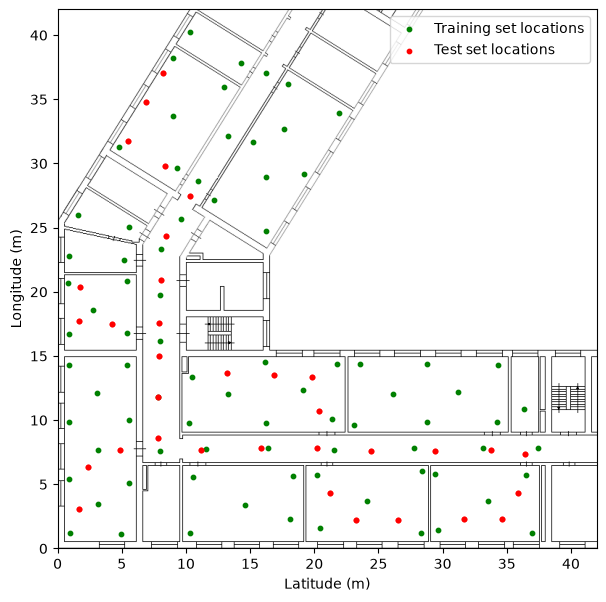

In [21]:
plot_plan(train_lat_lon, test_lat_lon)

## **Tasks**

**Task 1 - Positioning Using Coordinates (Regression Problem)**

**Step 1:** Using the LOOCV method, evaluate an unweighted KNN model with $k$ values ranging from 1 to 9 and a weighted KNN model with $k$ values ranging from 1 to 9. Use the positioning error (Euclidean distance) as the evaluation metric:

> `location_error = np.linalg.norm(validation_lat_lon - predicted_lat_lon, axis=1)`,

where `validation_lat_lon` are the true location coordinates and `predicted_lat_lon` are the predicted location coordinates, and `norm()` calculates the Euclidean distance.

*Note: It is not necessary to standardize the factor values for this data.*

**Step 2:** Select the best regression model (weighted or unweighted, and the $k$ value). Evaluate the average positioning error of this model on the test data. And, since this is actually a pair of models - as each coordinate has its own model - also evaluate each of these two models separately using the mean absolute error to determine the positioning error for each coordinate individually.

**Step 3:** Use `plot_plan(None, test_lat_lon, predicted_lat_lon)` to plot the test locations along with the model's predictions (arrows will point to the predicted locations).

**Step 4:** Write a concise analysis of everything obtained in the previous steps of this assignment - model evaluations, the best model, the positioning error of the best model, errors in individual coordinates, the positioning offset diagram, and overall conclusions.
<br>
<br>
**Task 2 - Room Detection (Classification Task)**

**Step 1:** Use the best $k$ values found in Task 1 and the decision on whether to use weighting or not to create a single classification model. Evaluate it on the test data using Accuracy and the macro F1 score.

**Step 2:** Create an error matrix. Since there are 10 classes in the dataset, the matrix will be 10x10.

**Step 3:** Write a concise analysis of everything obtained in the previous steps of this task - model evaluations, error matrix, and overall conclusions. Why do you think the room identification error(s) occurred specifically for that room (or those rooms)?

---
# Task 1 - Positioning Using Coordinates

## Step 1: LOOCV Evaluation for Unweighted and Weighted KNN Models (k=1-9)

LOOCV Positioning Errors for k = 1-9:

k    | Unweighted LOOCV Error (m) | Weighted LOOCV Error (m)
------------------------------------------------------------
1    | 4.0825                     | 4.0825                  
2    | 3.1879                     | 3.2320                  
3    | 3.3575                     | 3.2786                  
4    | 3.2234                     | 3.1140                  
5    | 3.5986                     | 3.3714                  
6    | 3.7403                     | 3.4332                  
7    | 3.9440                     | 3.5585                  
8    | 4.1225                     | 3.6795                  
9    | 4.1609                     | 3.7194                  


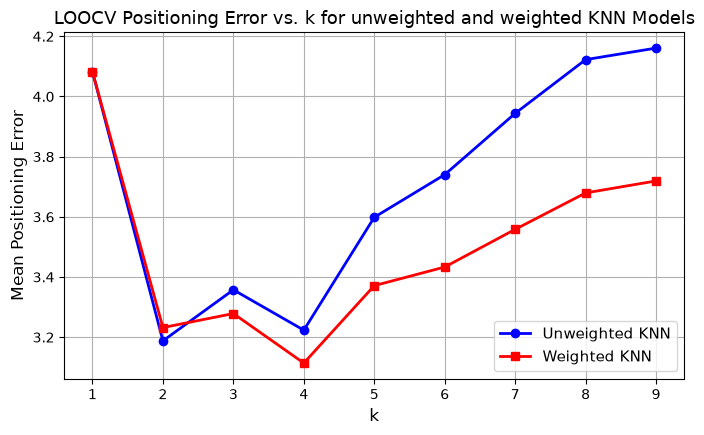

In [22]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_predict

k_values = range(1, 10)
loo = LeaveOneOut()

loocv_errors_unweighted = []
loocv_errors_weighted = []

print("LOOCV Positioning Errors for k = 1-9:\n")
print(f"{'k':<4} | {'Unweighted LOOCV Error (m)':<26} | {'Weighted LOOCV Error (m)':<24}")
print("-" * 60)

for k in k_values:
    # unweighted KNN
    knn_unweighted = KNeighborsRegressor(n_neighbors=k, weights='uniform')
    pred_unweighted = cross_val_predict(knn_unweighted, train_rss.values, train_lat_lon.values, cv=loo)
    err_unweighted = np.linalg.norm(train_lat_lon.values - pred_unweighted, axis=1).mean()
    loocv_errors_unweighted.append(err_unweighted)

    # weighted KNN
    knn_weighted = KNeighborsRegressor(n_neighbors=k, weights='distance')
    pred_weighted = cross_val_predict(knn_weighted, train_rss.values, train_lat_lon.values, cv=loo)
    err_weighted = np.linalg.norm(train_lat_lon.values - pred_weighted, axis=1).mean()
    loocv_errors_weighted.append(err_weighted)

    print(f"{k:<4} | {err_unweighted:<26.4f} | {err_weighted:<24.4f}")

# Plotting LOOCV positioning errors vs k
plt.figure(figsize=(8, 4.5))
plt.plot(k_values, loocv_errors_unweighted, 'b-o', label='Unweighted KNN', linewidth=2)
plt.plot(k_values, loocv_errors_weighted, 'r-s', label='Weighted KNN', linewidth=2)
plt.xlabel('k', fontsize=12)
plt.ylabel('Mean Positioning Error', fontsize=12)
plt.title('LOOCV Positioning Error vs. k for unweighted and weighted KNN Models', fontsize=13)
plt.xticks(k_values)
plt.grid(True)
plt.legend(fontsize=11)
plt.show()

## Step 2: Best Regression Model Selection and Evaluation on Test Data

In [23]:
from sklearn.metrics import mean_absolute_error

# Best model : weighted KNN with k = 4
best_k = 4
best_weights = 'distance'

knn_lat = KNeighborsRegressor(n_neighbors=best_k, weights=best_weights)
knn_lon = KNeighborsRegressor(n_neighbors=best_k, weights=best_weights)

knn_lat.fit(train_rss.values, train_lat_lon['Latitude'].values)
knn_lon.fit(train_rss.values, train_lat_lon['Longitude'].values)

pred_lat = knn_lat.predict(test_rss.values)
pred_lon = knn_lon.predict(test_rss.values)
predicted_lat_lon = np.column_stack([pred_lat, pred_lon])

test_pos_errors = np.linalg.norm(test_lat_lon.values - predicted_lat_lon, axis=1)
mean_test_pos_error = np.mean(test_pos_errors)

mae_latitude = mean_absolute_error(test_lat_lon['Latitude'].values, pred_lat)
mae_longitude = mean_absolute_error(test_lat_lon['Longitude'].values, pred_lon)

print(f"Selected Best Model: weighted KNN k = 4")
print(f"Average Positioning Error on Test Data: {mean_test_pos_error:.4f} m")
print(f"Latitude Mean Absolute Error:     {mae_latitude:.4f} m")
print(f"Longitude Mean Absolute Error:    {mae_longitude:.4f} m")

Selected Best Model: weighted KNN k = 4
Average Positioning Error on Test Data: 2.1381 m
Latitude Mean Absolute Error:     1.5419 m
Longitude Mean Absolute Error:    1.0161 m


## Step 3: Plotting Test Locations and Model Predictions

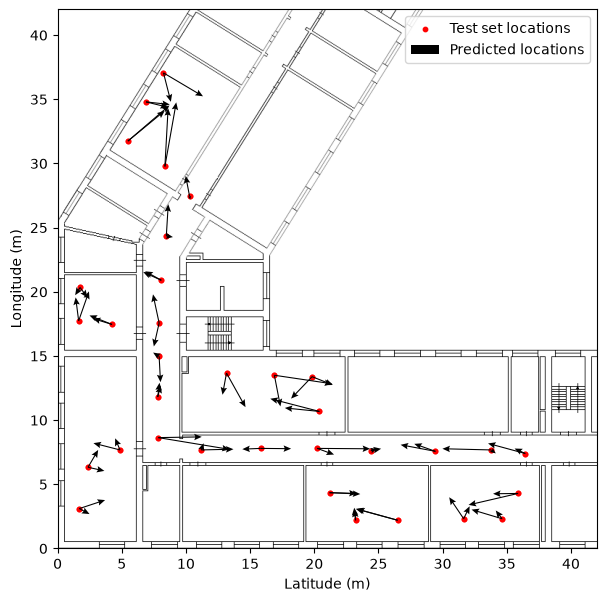

In [24]:
plot_plan(None, test_lat_lon, predicted_lat_lon)

## Step 4: Analysis of Task 1
### 1. Model Evaluations & Selection of the best model
- Using LOOCV the unweighted and distance-weighted KNN models for neighbors sizes k = 1-9 have been evaluated.
- At k = 1 both unweighted and weighted models produced identical mean positioning error 4.0825m because inverse-distance weighting on a single nearest neighbor has no relative scaling effect.
- For k > 3 distance weighted KNN consistently outperforms unweighted KNN. It reduces the influence of farther, less representative neighbors.
- The minimum LOOCV positioning error across all tested values was achieved with a weighted KNN with k = 4 (error was 3.1140m), which outperformed the best unweighted model.
### 2.Evaluation on Test Data & Individual Coordinate Errors
- On the unseen test dataset, the selected best model achieved an average Euclidean positioning error of 2.1381m. This shows strong generalization performance.
- The mean absolute error was 1.5419m for the latitude model and 1.0161m for the longitude model. Better accuracy in longitude estimations aligns with the spatial distribution of the access points and the rectangular floor layout along the hallway axes.
### 3. Positioning Offset Diagram Observations
- The plot illustrates the test positions (red dots) and the error displacement vectors pointing toward the predicted location.
- The error arrows are generally short across the entire building, which indicates high consistency.
- Along hallway sections, the error vectors align mainly along the hallway direction rather than cutting across physical solid walls.
### Overall Conclusions
- Distance-weighted KNN regression effectively utilizes multi-dimensional Wi-Fi RSS fingerprints for continuous indoor coordinate estimation.
- A value of k = 4 combined with inverse-distance weighting provides the optimal balance between smoothing measurement noise and preserving localized spatial precision.

---
# Task 2: Room Detection

## Step 1: Classification Model Evaluation on Test Data

In [25]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

clf = KNeighborsClassifier(n_neighbors=4, weights='distance')
clf.fit(train_rss.values, train_room['RoomID'].values)

pred_room = clf.predict(test_rss.values)

acc = accuracy_score(test_room['RoomID'].values, pred_room)
macro_f1 = f1_score(test_room['RoomID'].values, pred_room, average='macro')

print(f"Classification Model: Weighted KNN Classifier (k = 4, weights='distance')")
print(f"Accuracy:        {acc:.4f} ({acc * 100:.2f}%)")
print(f"Macro F1-Score:  {macro_f1:.4f}")

Classification Model: Weighted KNN Classifier (k = 4, weights='distance')
Accuracy:        0.9853 (98.53%)
Macro F1-Score:  0.9619


## Step 2: Error Matrix

Confusion Matrix (10x10):

[[ 1  1  0  0  0  0  0  0  0  0]
 [ 0 10  0  0  0  0  0  0  0  0]
 [ 0  0  8  0  0  0  0  0  0  0]
 [ 0  0  0  8  0  0  0  0  0  0]
 [ 0  0  0  0  6  0  0  0  0  0]
 [ 0  0  0  0  0  6  0  0  0  0]
 [ 0  0  0  0  0  0  8  0  0  0]
 [ 0  0  0  0  0  0  0  6  0  0]
 [ 0  0  0  0  0  0  0  0  6  0]
 [ 0  0  0  0  0  0  0  0  0  8]]


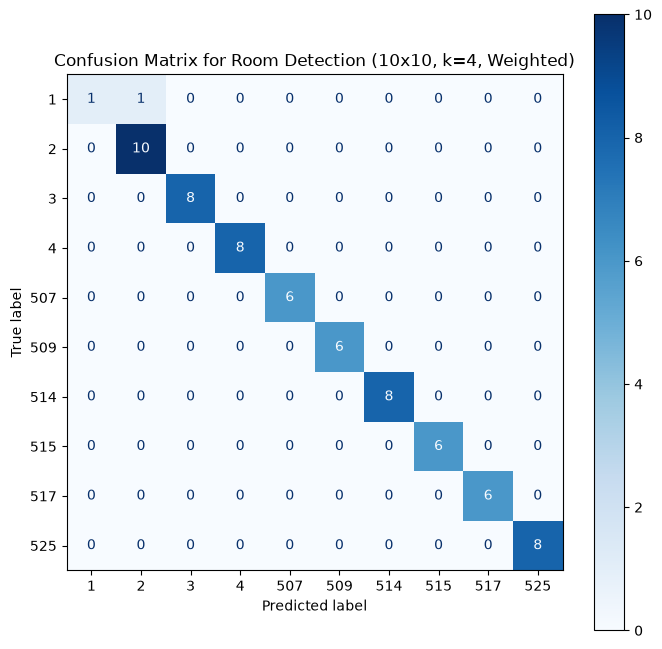

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(test_room['RoomID'].values, pred_room)
print("Confusion Matrix (10x10):\n")
print(cm)

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    test_room['RoomID'].values, 
    pred_room, 
    ax=ax, 
    cmap='Blues'
)
plt.title("Confusion Matrix for Room Detection (10x10, k=4, Weighted)")
plt.grid(False)
plt.show()

## Step 3:  Analysis for Task 2
### 1. Model Evaluations & Performance
- Using the optimal hyperparameter settings identified in Task 1 (k = 4, inverse-distance weighting), the classification model achieved an accuracy of 98.53% (just one test point incorrectly classified) and a macro f1 score of 0.9619 on the test dataset.
### 2. Error Matrix
- The 10 by 10 confusion matrix is almost perfectly diagonal.
- All enclosed lecture halls and offices as well as hallway sections 2, 3 and 4 achieved 100% precision and recall with zero misclassifications.
- Out of all 68 test samples, exactly one single misclassification occurred: one sample belonging to Room 1 was predicted as Room 2 (test index 35).
### 3. Why the Room Identification Error Occurred
- Single-digit room numbers (1, 2, 3, 4) represent consecutive sections of an open, continuous hallway, whereas three-digit room numbers represent enclosed rooms.
- Unlike enclosed offices and lecture halls that are separated by physical walls and doors (which shield the WIFI signal), hallway sections 1 and 2 share an open, seamless boundary without any physical walls or barriers.
- The misclassified test sample (test index 35) lies directly at the geometrix dividing threshold between hallway section 1 and section 2 (lat = 10.28m, lon = 27.46m).
### 4. Overall Conclusions
- WIFI RSS fingerprinting with weighted KNN with k = 4 is accurate for indoor room detection.
- Misclassifications are only ocurring at virtual partitions within continuous open space like corridors, while physical room boundaries are separated reliable.

---
Assignee: Jakob Benedikt Wilmesmeier

*While doing the tasks you are allowed to use only those function libraries that were already used in the lectures so far.*

**After the tasks are done, submit this file. Do not clear it's output - all print-outs and figures should be left in the file. All your code should be fully runnable in the order of appearance and it should produce exactly the same output that is present in your print-outs and figures you left in the file.**